<a href="https://colab.research.google.com/github/Decode333/protobridge-python/blob/master/DL/DL_Task.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [47]:
import keras
from keras.models import Sequential
from keras.layers import Dense, Flatten
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [5]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
assert x_train.shape == (50000, 32, 32, 3)
assert x_test.shape == (10000, 32, 32, 3)
assert y_train.shape == (50000, 1)
assert y_test.shape == (10000, 1)


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1288s 8us/step


In [7]:
# normalize the data
x_train = x_train / 255
x_test = x_test / 255

In [8]:
# Model building

model = Sequential()
model.add(Flatten(input_shape=(32, 32, 3)))
model.add(Dense(128, activation='relu'))
model.add(Dense(10, activation='softmax'))

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['sparse_categorical_accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [11]:
# Model training

model.fit(x_train, y_train, epochs=100, batch_size=100, validation_data=(x_test, y_test))

Epoch 1/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 1.5859 - sparse_categorical_accuracy: 0.4380 - val_loss: 1.6019 - val_sparse_categorical_accuracy: 0.4309
Epoch 2/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1.5746 - sparse_categorical_accuracy: 0.4436 - val_loss: 1.6397 - val_sparse_categorical_accuracy: 0.4246
Epoch 3/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1.5725 - sparse_categorical_accuracy: 0.4428 - val_loss: 1.5810 - val_sparse_categorical_accuracy: 0.4371
Epoch 4/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1.5646 - sparse_categorical_accuracy: 0.4454 - val_loss: 1.6900 - val_sparse_categorical_accuracy: 0.4075
Epoch 5/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1.5563 - sparse_categorical_accuracy: 0.4493 - val_loss: 1.5761 - val_sparse_categorical_accuracy: 0.4443
Epoch 6/100
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1.5487 - sparse_categorical_accuracy: 0.4540 - val_loss: 1.5935 - val_sparse_categorical_accuracy: 0.437

### Improving the MLP (Dense-only) Model

To improve the model without using any convolutional layers, we will construct a deeper dense neural network with Dropout and Batch Normalization to prevent overfitting and accelerate training.

In [30]:
from keras.layers import Dense, Flatten, Dropout, BatchNormalization
from keras.models import Sequential

# Build a deeper and optimized MLP model
mlp_model = Sequential([
    Flatten(input_shape=(32, 32, 3)),

    Dense(512, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),

    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),

    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),

    Dense(10, activation='softmax')
])

# Compile the optimized MLP model
mlp_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['sparse_categorical_accuracy']
)

mlp_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │     1,573,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,742,474 (6.65 MB)

 Trainable params: 1,740,682 (6.64 MB)

 Non-trainable params: 1,792 (7.00 KB)

In [31]:
# Train the optimized MLP model
history_mlp = mlp_model.fit(
    x_train, y_train,
    epochs=30,
    batch_size=128,
    validation_data=(x_test, y_test)
)

Epoch 1/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 14s 19ms/step - loss: 2.0176 - sparse_categorical_accuracy: 0.3065 - val_loss: 2.0588 - val_sparse_categorical_accuracy: 0.2736
Epoch 2/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 1.7240 - sparse_categorical_accuracy: 0.3824 - val_loss: 1.7787 - val_sparse_categorical_accuracy: 0.3604
Epoch 3/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 1.6568 - sparse_categorical_accuracy: 0.4083 - val_loss: 1.6671 - val_sparse_categorical_accuracy: 0.4033
Epoch 4/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 1.6088 - sparse_categorical_accuracy: 0.4256 - val_loss: 1.5506 - val_sparse_categorical_accuracy: 0.4456
Epoch 5/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 1.5935 - sparse_categorical_accuracy: 0.4300 - val_loss: 1.5855 - val_sparse_categorical_accuracy: 0.4319
Epoch 6/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 1.5865 - sparse_categorical_accuracy: 0.4346 - val_loss: 1.6041 - val_sparse_categorical_accuracy: 0.4150
Ep

In [32]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       393,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,183,904 (4.52 MB)

 Trainable params: 394,634 (1.51 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 789,270 (3.01 MB)

In [33]:
# Save the model
model.save('cifar10_model.h5')

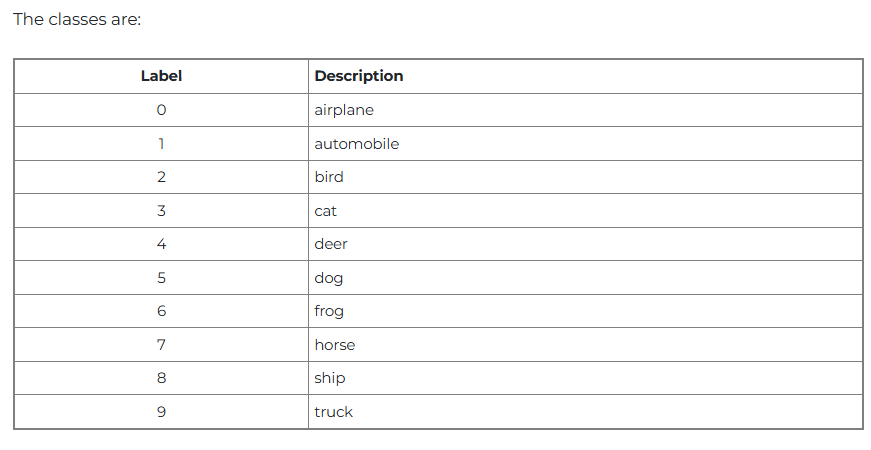

In [39]:
y_test[250]

array([5], dtype=uint8)

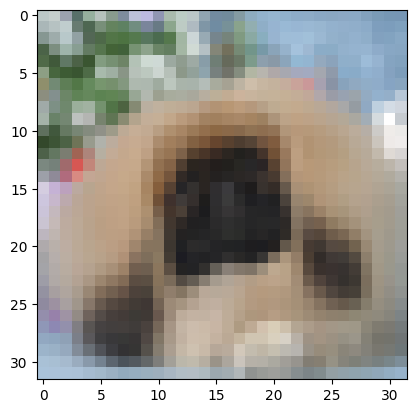

In [40]:
plt.imshow(x_test[250])

In [41]:
predicted = model.predict(x_test[250].reshape(1, 32, 32, 3))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step


In [43]:
np.argmax(predicted)

np.int64(3)

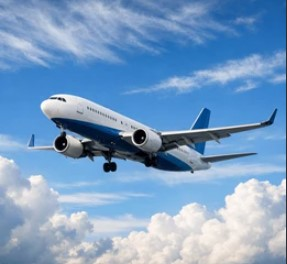

In [48]:
Image.open("/content/aeroplane.jpg")

In [55]:
image = Image.open("/content/aeroplane.jpg").convert("L").resize((32,32))
image = np.array(image)
image = image/255.0
image = np.expand_dims(image, axis=0)
image.shape

(1, 32, 32)

In [58]:
# Load and preprocess the image properly in RGB mode (3 channels)
rgb_image = Image.open("/content/aeroplane.jpg").convert("RGB").resize((32, 32))
rgb_image_array = np.array(rgb_image) / 255.0
rgb_image_batch = np.expand_dims(rgb_image_array, axis=0)

# Run prediction
img_pred = model.predict(rgb_image_batch)
print("Predicted Class Index:", np.argmax(img_pred))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
Predicted Class Index: 0
